# Prototype 3 — Synthetic Student Tuning

_From "Wicked Problem Prototypes: Personalization Without the Data Districts Can't Defend" (Linda Bernard, Nov 2026)._

**ACE is developed and calibrated on simulated middle schoolers, so real student data is needed only for validation at low volume, and never for model development.**

This notebook walks through the harness and the rigor layer built on top of it. It answers the obvious objection to the two-stream model: *if QuestSim never gets student data, how does the product get better?*

> The figures come from `run.py`. Re-run the cells to regenerate them (deterministic).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
from synthetic_tuning import sample_population, SKILL_NAMES, FT_TARGET, SCAF_TARGET
from synthetic_tuning import validation as V, analysis as A, plotting
from IPython.display import Image
print('skills:', SKILL_NAMES)

skills: ['square_numbers', 'square_roots', 'identify_hyp', 'theorem_setup', 'solve_hyp', 'solve_leg', 'word_problems']


## 1. The synthetic population — six grounded parameters

Each learner is an agent with **six** parameters, each grounded in published learning-science literature, and the skill sequence is cumulative (a mastered prerequisite raises the next skill's prior):

| parameter | grounding |
|---|---|
| prior knowledge | BKT — Corbett & Anderson (1995) |
| learning rate | power law of practice — Newell & Rosenbloom (1981) |
| slip (error tendency) | BKT slip |
| guessing / gaming | Baker et al. (2008) |
| hint-seeking | Aleven et al. (2006) |
| forgetting rate | Ebbinghaus; Pavlik & Anderson (2005) |

In [2]:
syn = sample_population(200, seed=1, shift=0.0)      # optimistic prior
real = V.build_real_cohort()                         # harder + forgetting tail
for p in ('prior','learn_mult','slip_mult','guess_mult','hint','decay'):
    print(f'{p:12s} synthetic mean={syn[p].mean():.2f}   real mean={real[p].mean():.2f}')

prior        synthetic mean=0.19   real mean=0.15
learn_mult   synthetic mean=0.97   real mean=0.46
slip_mult    synthetic mean=1.01   real mean=1.65
guess_mult   synthetic mean=0.97   real mean=1.08
hint         synthetic mean=0.35   real mean=0.42
decay        synthetic mean=0.20   real mean=0.30


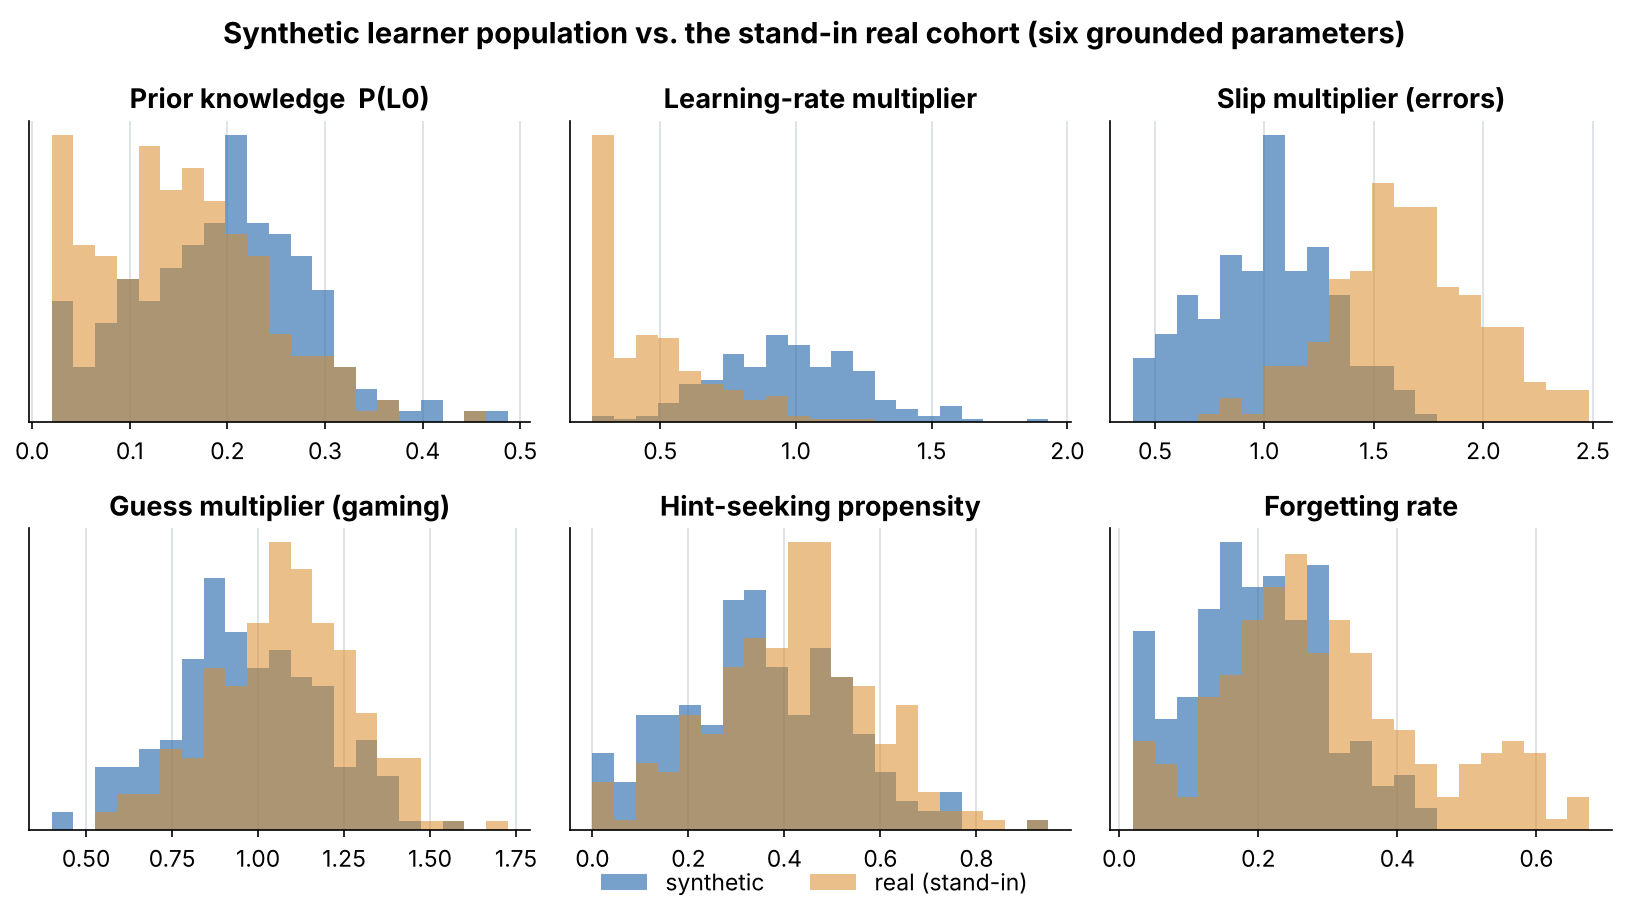

In [3]:
plotting.plot_population(syn, real, '../figures/01_population.png')
Image('../figures/01_population.png')

## 2. Calibration curves for ACE's triggers

ACE tracks per-skill mastery with Bayesian Knowledge Tracing and fires **fast-track** (advance a quick master) and **scaffold** (support a struggler). Each is governed by one threshold; the calibration curve sweeps it and reports the cohort firing rate, so we can hit a design target (fast-track ~15%, scaffold ~35%).

chosen thresholds: fast-track 0.92  scaffold 0.75


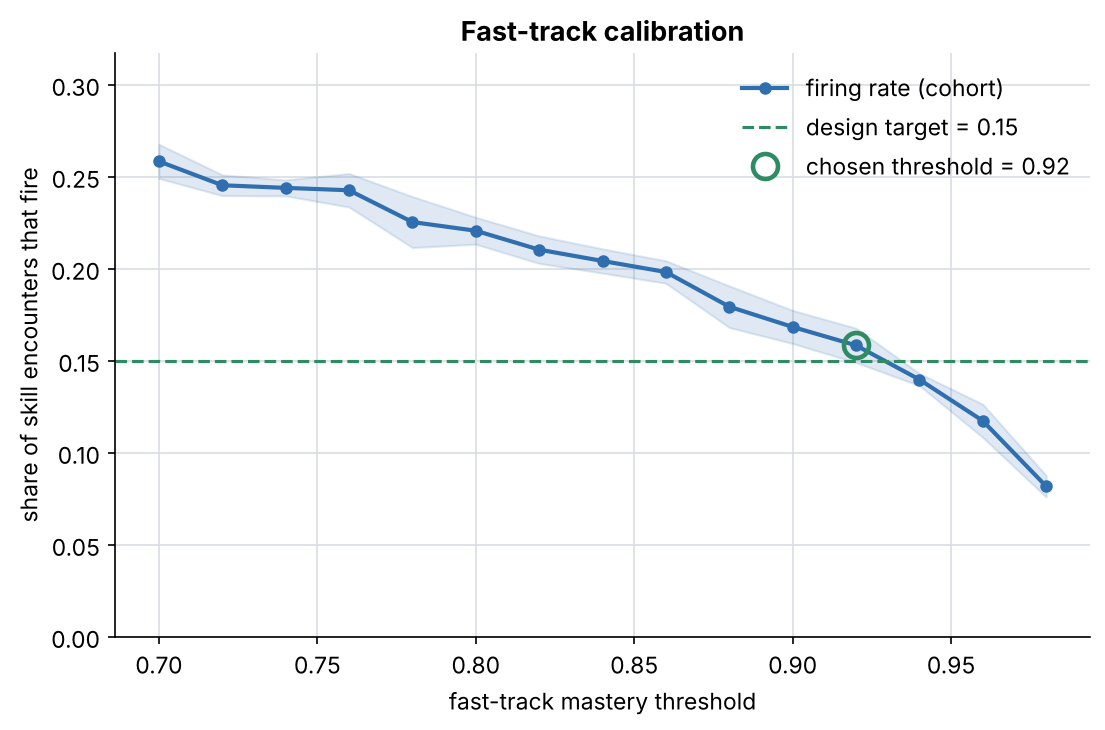

In [4]:
from synthetic_tuning import calibrate, pick_threshold, FT_GRID, SCAF_GRID
ft_curve = calibrate(syn, 'ft_thr', FT_GRID)
sc_curve = calibrate(syn, 'scaf_thr', SCAF_GRID)
ft_thr = pick_threshold(ft_curve, FT_TARGET)
sc_thr = pick_threshold(sc_curve, SCAF_TARGET)
plotting.plot_calibration(ft_curve, FT_TARGET, ft_thr, 'Fast-track calibration', '../figures/02_calibration_fasttrack.png', 'fast-track mastery threshold')
plotting.plot_calibration(sc_curve, SCAF_TARGET, sc_thr, 'Scaffold calibration', '../figures/03_calibration_scaffold.png', 'scaffold struggle threshold')
print('chosen thresholds: fast-track', ft_thr, ' scaffold', sc_thr)
Image('../figures/02_calibration_fasttrack.png')

## 3. The test — within range (pre-registered criterion)

The criterion is set **before** running: mean mastery ±0.03, bottom-quartile ±0.05, retention ±0.03, opportunities/skill ±1.0. Both engines are evaluated on the real cohort over several resamples, so each delta carries a confidence band.

criterion: {'mean_mastery': 0.03, 'bottom_quartile_mastery': 0.05, 'retention': 0.03, 'opportunities_per_skill': 1.0}


  mean_mastery               delta=0.012 ± 0.007  PASS
  bottom_quartile_mastery    delta=0.010 ± 0.016  PASS
  retention                  delta=0.009 ± 0.006  PASS
  opportunities_per_skill    delta=0.198 ± 0.095  PASS
OVERALL: PASS


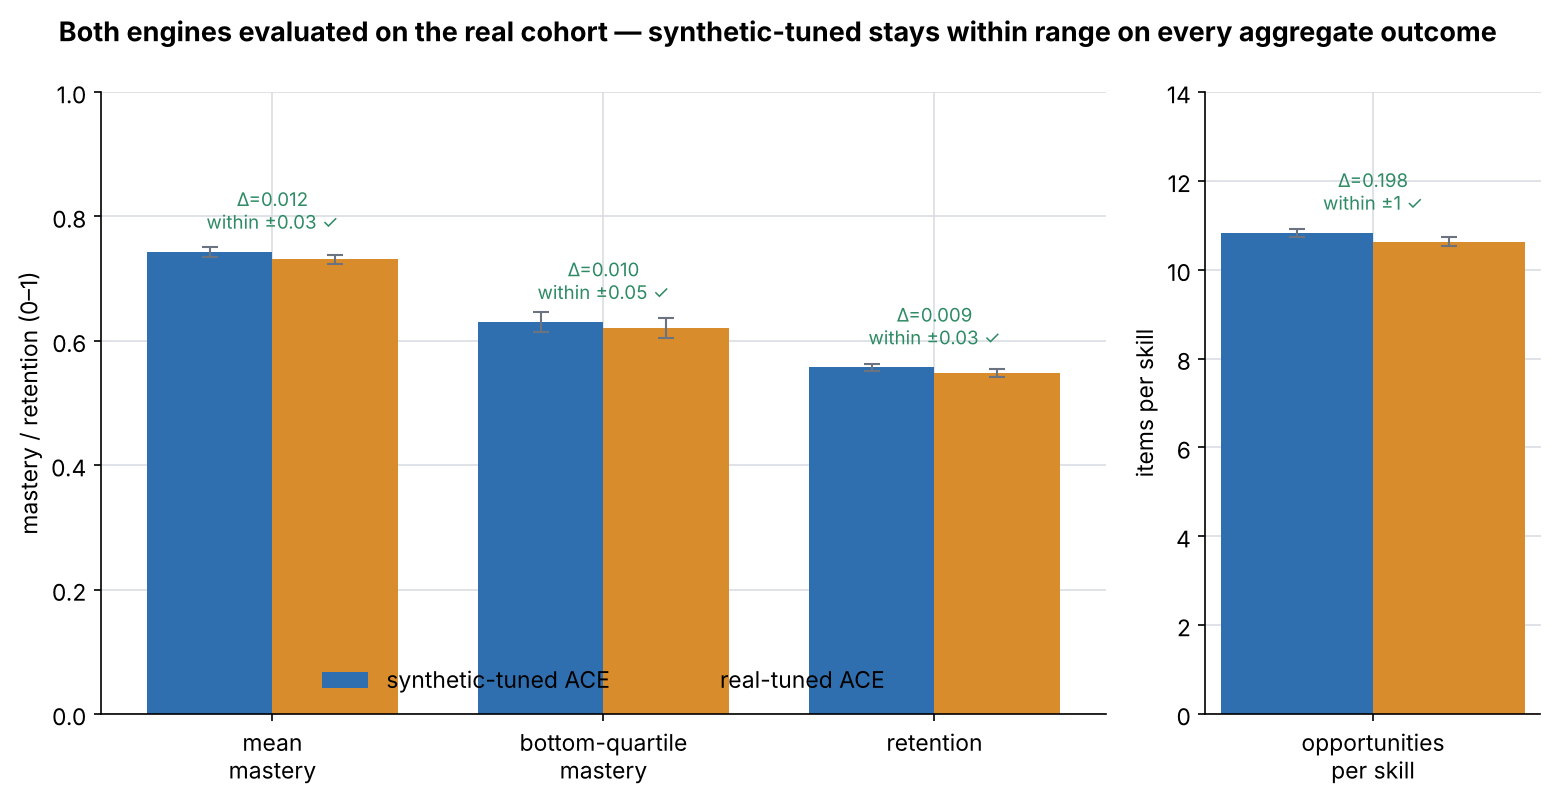

In [5]:
print('criterion:', V.WITHIN_RANGE)
wr = V.within_range_test(syn, real)
for k in V.OUTCOME_KEYS:
    print(f"  {k:26s} delta={wr['deltas'][k]:.3f} ± {wr['delta_std'][k]:.3f}  {'PASS' if wr['passed'][k] else 'FAIL'}")
print('OVERALL:', 'PASS' if wr['overall_pass'] else 'FAIL')
plotting.plot_within_range(wr, V.WITHIN_RANGE, '../figures/04_within_range.png')
Image('../figures/04_within_range.png')

## 4. Transfer and aggregate-only feedback

A scaffold improvement found on synthetic data is applied to the real cohort (no record leaves). Then the only real-world input — **one number**, the real cohort's fast-track rate — re-grounds the synthetic population's difficulty.

transfer: real bottom-quartile 0.644 -> 0.663 (transfers=True)


feedback: real ft-rate 0.051 -> recovered shift 0.60 (true 0.60)


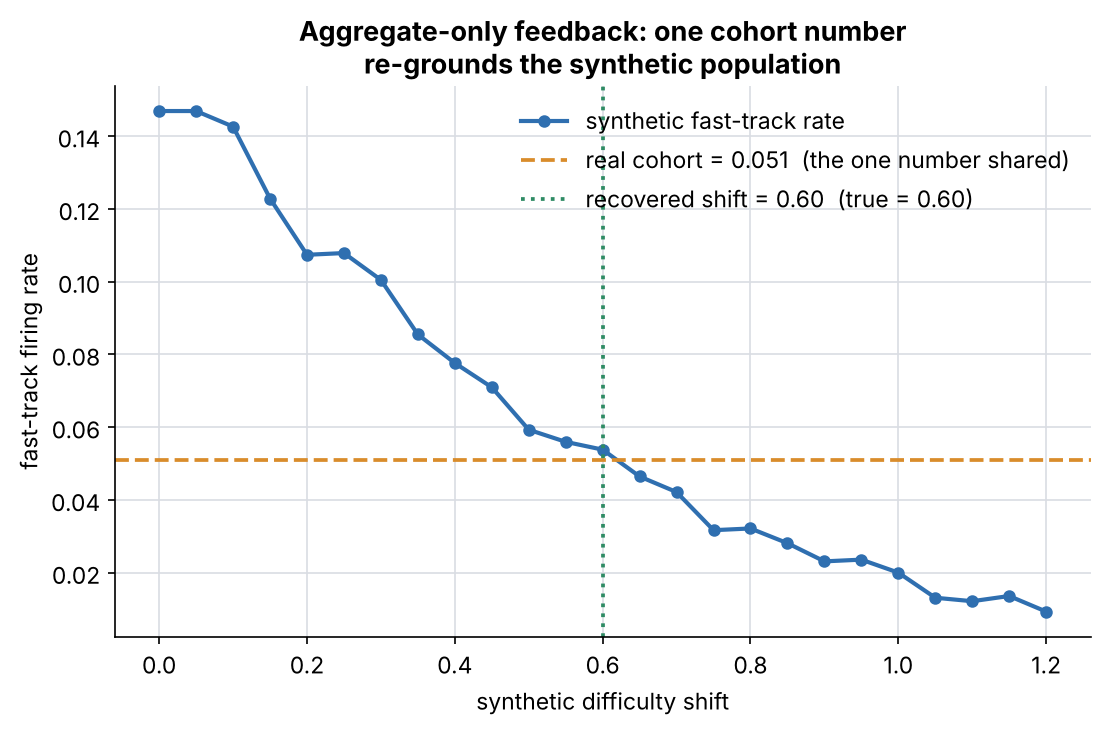

In [6]:
tr = V.transfer_test(syn, real, wr['syn_tuned']['scaf_thr'])
print(f"transfer: real bottom-quartile {tr['real_before']:.3f} -> {tr['real_after']:.3f} (transfers={tr['transfers']})")
af = V.aggregate_feedback(real, wr['syn_tuned']['ft_thr'])
print(f"feedback: real ft-rate {af['real_ft_rate']:.3f} -> recovered shift {af['recovered_shift']:.2f} (true {af['true_shift']:.2f})")
plotting.plot_transfer(tr, '../figures/05_transfer.png')
plotting.plot_feedback(af, '../figures/06_aggregate_feedback.png')
Image('../figures/06_aggregate_feedback.png')

## 5. Rigor — does the loop recover *known* difficulty?

Parameter recovery: build cohorts at a range of known difficulty shifts, feed one aggregate number back each time, and measure the recovery error. Low error means the aggregate-only loop identifies real difficulty rather than fitting noise.

recovery MAE = 0.017
  true=0.0 recovered=0.00±0.00
  true=0.3 recovered=0.28±0.06
  true=0.6 recovered=0.58±0.05
  true=0.9 recovered=0.87±0.02


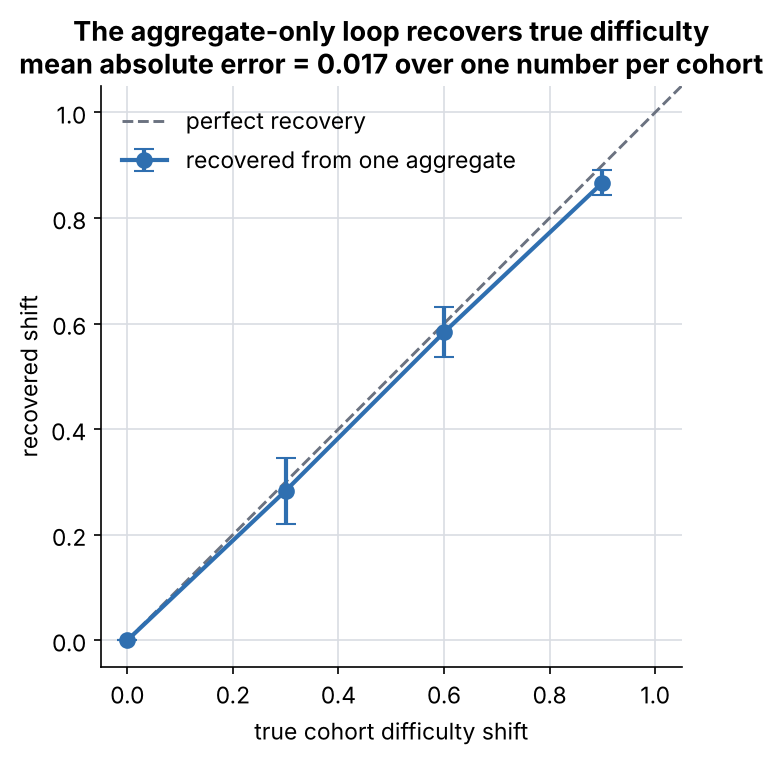

In [7]:
rec = A.parameter_recovery(ft_thr=wr['syn_tuned']['ft_thr'], n_trials=3)
print('recovery MAE =', round(rec['mae'],3))
for r in rec['rows']: print(f"  true={r['true']:.1f} recovered={r['recovered_mean']:.2f}±{r['recovered_std']:.2f}")
plotting.plot_parameter_recovery(rec, '../figures/08_parameter_recovery.png')
Image('../figures/08_parameter_recovery.png')

## 6. Rigor — does it generalise across cohort shapes?

The core demo uses one stand-in real cohort. Here the whole test is re-run against five shapes — a uniform harder cohort, a forgetting tail, a bimodal split, a high-gaming cohort, and a slow-acquisition cohort. Synthetic tuning holds on the immediate outcomes everywhere; the retention blind spot varies with the shape.

  uniform_harder    within-range PASS · retention gap 0.028
  forgetting_tail   within-range PASS · retention gap 0.014
  bimodal           within-range PASS · retention gap 0.076
  high_gaming       within-range PASS · retention gap 0.108
  slow_acquisition  within-range PASS · retention gap 0.027


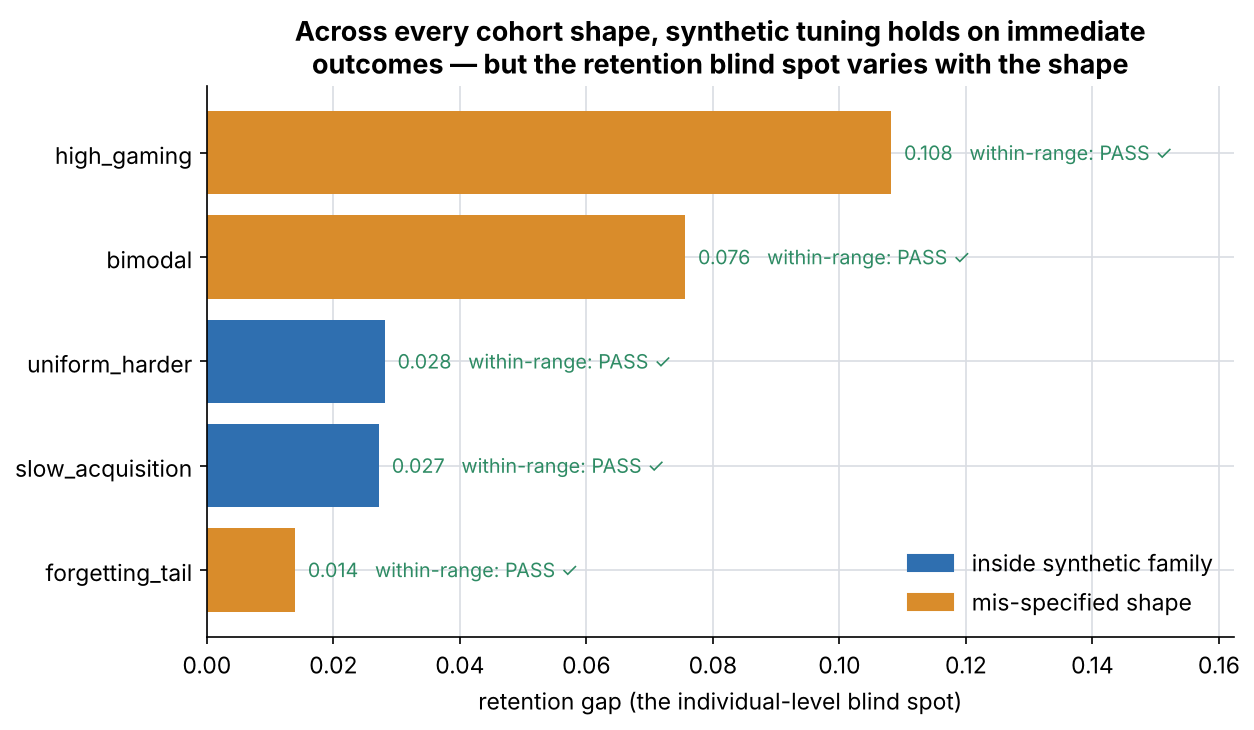

In [8]:
scen = V.run_scenarios(syn)
for name, r in scen.items():
    print(f"  {name:17s} within-range {'PASS' if r['overall_pass'] else 'FAIL'} · retention gap {r['retention_gap']:.3f}")
plotting.plot_scenarios(scen, '../figures/09_scenarios.png')
Image('../figures/09_scenarios.png')

## 7. Rigor — sensitivity and confidence intervals

One-at-a-time sweeps of the (unknown) real-cohort assumptions, and bootstrap 95% intervals on the headline numbers. The within-range result is robust; the quantity that moves is the retention gap — which a real pilot would pin down.

retention gap spans 0.0 - 0.108


recovered shift 0.58 [0.50, 0.64]
retention gap   0.027 [0.004, 0.050]


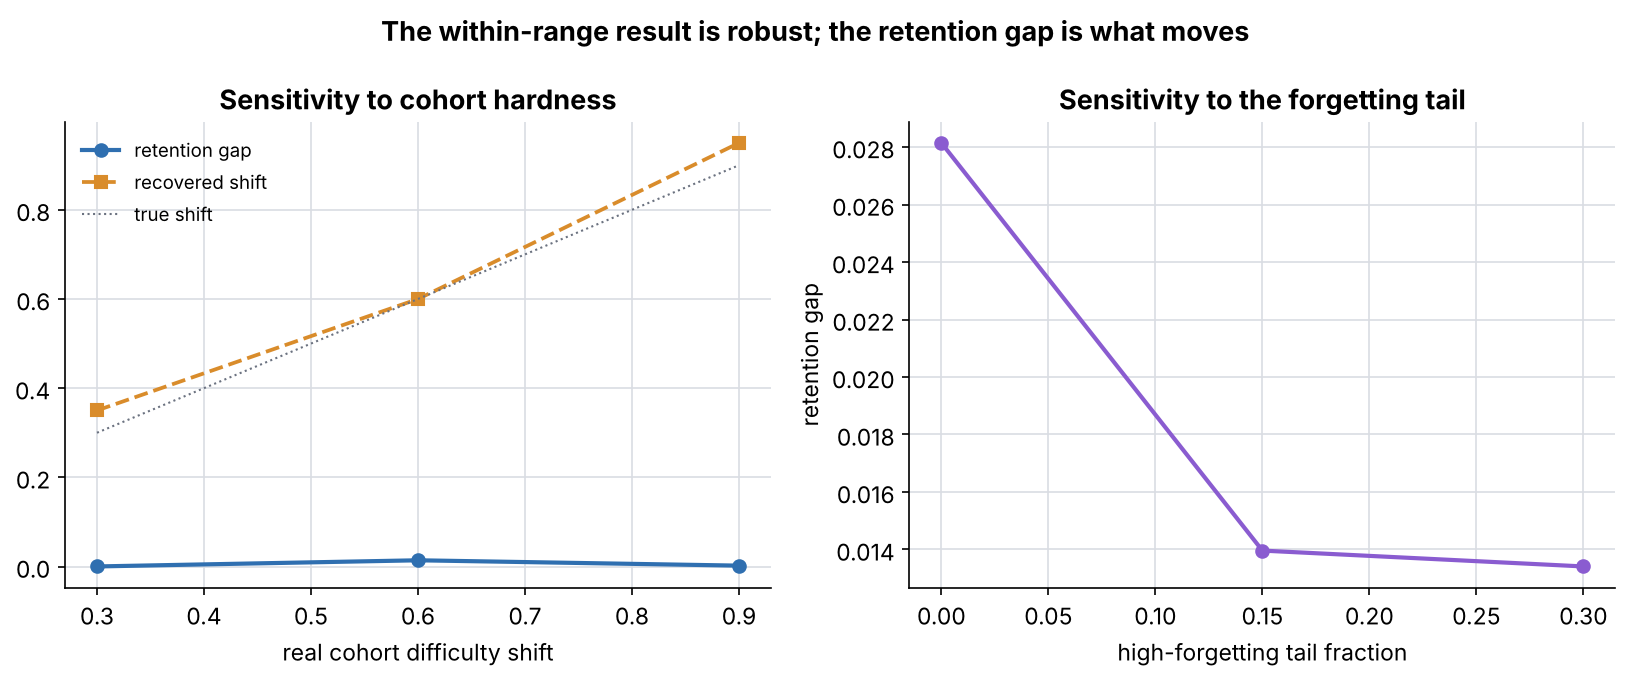

In [9]:
sens = A.sensitivity(ft_thr=wr['syn_tuned']['ft_thr'])
print('retention gap spans', round(sens['retention_gap_min'],3), '-', round(sens['retention_gap_max'],3))
boot = A.bootstrap_ci(ft_thr=wr['syn_tuned']['ft_thr'], n_boot=10)
rs, rg = boot['recovered_shift'], boot['retention_gap']
print(f"recovered shift {rs['mean']:.2f} [{rs['lo']:.2f}, {rs['hi']:.2f}]")
print(f"retention gap   {rg['mean']:.3f} [{rg['lo']:.3f}, {rg['hi']:.3f}]")
plotting.plot_sensitivity(sens, '../figures/10_sensitivity.png')
Image('../figures/10_sensitivity.png')

## 8. The caveat (state this in class)

A synthetic population tuned to match real aggregates can still be wrong about individuals in ways that only show up in real classrooms. The scenario sweep makes it concrete: tuning holds on immediate outcomes, but the retention gap — invisible to the aggregate the loop used — is real and largest for the mis-specified cohorts. That is why the two streams validate each other rather than one replacing the other.

mean-mastery gap (matched) = 0.006
retention gap (blind spot) = 0.014


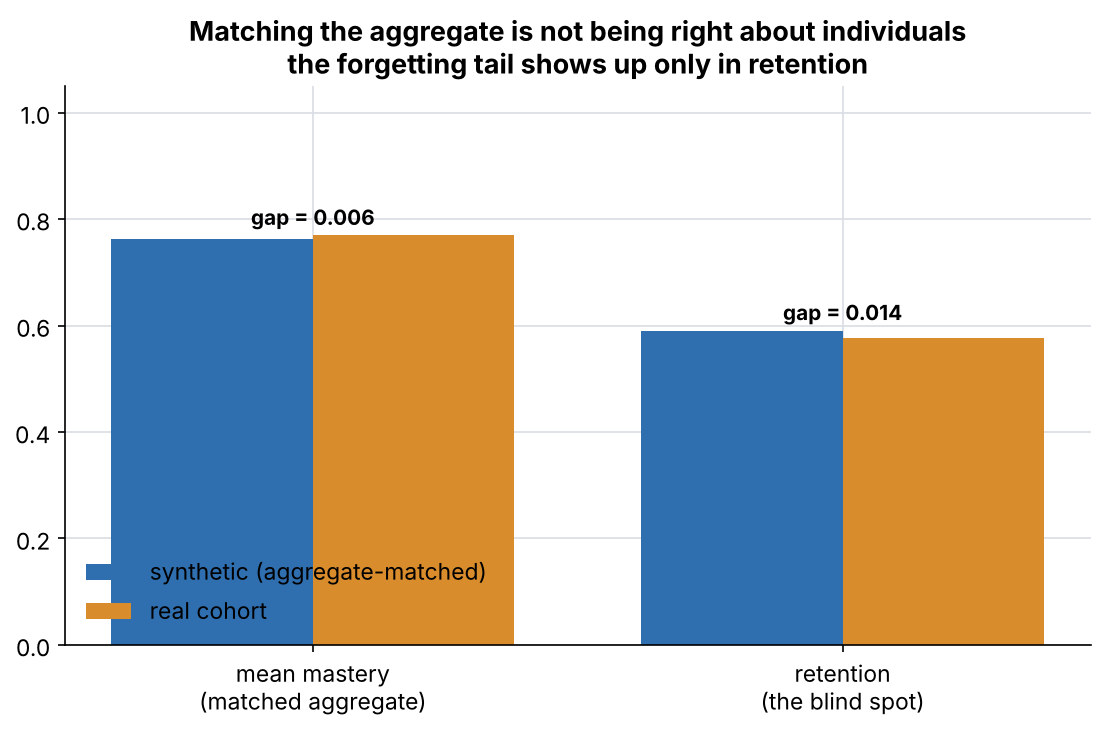

In [10]:
cv = V.caveat_demo(real, af['recovered_shift'])
print(f"mean-mastery gap (matched) = {cv['mastery_gap']:.3f}")
print(f"retention gap (blind spot) = {cv['retention_gap']:.3f}")
plotting.plot_caveat(cv, '../figures/07_caveat_retention.png')
Image('../figures/07_caveat_retention.png')

## 9. Ready for real data — the live-data hook

The feedback loop can read a real cohort's **one number** from a district file. It enforces a minimum cohort size and refuses any file carrying a per-student field, so only an aggregate is ever consumed.

In [11]:
from synthetic_tuning.real_data import reground_from_file, load_aggregate, AggregateError
# the notebook runs from notebook/, so examples/ is one level up
out = reground_from_file('../examples/real_aggregate.json', ft_thr=wr['syn_tuned']['ft_thr'])
print('loaded:', out['source'])
print('recovered shift from the district number:', out['recovered_shift'])
# the guardrails refuse anything that is not an acceptable aggregate:
import json, tempfile, os as _os
p = tempfile.mktemp(suffix='.json'); open(p,'w').write(json.dumps({'fast_track_rate':0.05,'cohort_size':10}))
try: load_aggregate(p)
except AggregateError as e: print('small cohort refused ->', str(e)[:50])
_os.remove(p)

loaded: {'label': 'Maple Grove USD — spring Pythagoras pilot', 'cohort_size': 180, 'fast_track_rate': 0.047}
recovered shift from the district number: 0.65
small cohort refused -> Cohort size 10 is below the minimum of 30. A small


## What this answers

> We built the brain on simulated students; your kids only ever confirm it works.

Synthetic tuning holds across cohort shapes on the immediate outcomes, recovers true difficulty from a single aggregate, and transfers improvements to real cohorts — all without an individual record leaving the district. What it cannot see on its own (retention under mis-specification) is exactly what low-volume aggregate validation is for.